# Single-Region Comprehensive Validation Pipeline
This notebook executes an end-to-end evaluation for a single calorimeter kinematic region ($E_T \times \eta$):
1. **Split Manifest & Class Balance**: Analyzes signal (photons) vs background (jets) counts in the holdout test partition.
2. **Feature Distributions & Derived Variables**: Computes and visualizes raw features and calculated shower shapes (including $E_{\text{ratio}}$) with class separations.
3. **Training & Metric Curves**: Aggregates fold repeats and renders training loss, SP index, and ROC curves.
4. **Efficiency Validation**: Evaluates detection efficiency and false-alarm response against baseline thresholds.
5. **Quadrant Analysis (Model vs Cut)**: Benchmarks the best model against Athena fast photon linear cuts.
6. **Feature Distributions with Model Selections**: Overlays accepted events (black dots) on signal/background feature histograms for both the ML model and linear cuts.
7. **Model vs Model Comparison**: Executes holdout quadrant comparison against a secondary model configuration.



In [50]:
%load_ext autoreload
%autoreload 2

import os
import sys
from pathlib import Path

# Resolve repository root
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import torch
import yaml
import matplotlib.pyplot as plt
import mplhep as mh

mh.style.use("ATLAS")

from src.Parser.NeuralRingerTrainerConfiguration import NeuralRingerTrainerConfiguration
from src.core.Trainers.NeuralRingerTrainer import NeuralRingerTrainer
from src.core.Datasets.SplitManifest import SplitManifest
from src.core.Validation.ResultAggregator import ResultAggregator
from src.core.Validation.HoldoutEvaluator import HoldoutEvaluator, HoldoutEvaluationResult
from src.core.Validation.EfficiencyPlotter import EfficiencyPlotter
from src.core.Validation.QuadrantAnalyzer import QuadrantAnalyzer, StrategyMetrics
from scipy import stats
from src.core.Plotting.QuadrantPlotter import QuadrantPlotter
from src.core.Plotting.PlotManager import PlotManager
from src.utils import get_et_eta

print(f"Project root: {PROJECT_ROOT}")
print(f"PyTorch version: {torch.__version__}, CUDA available: {torch.cuda.is_available()}")


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Project root: /eos/home-i04/p/pmourafr/egamma_master
PyTorch version: 2.10.0, CUDA available: True


### Centralized Configuration Constants
All parameters, paths, and region selections are defined below:



In [56]:
# --- Target Kinematic Region ---
TARGET_ET: int = 1
TARGET_ETA: int = 1
REGION_KEY: str = f"et_{TARGET_ET}_eta_{TARGET_ETA}"

# --- Model 1 (Primary Model) Paths ---
CONFIG_PATH_1: Path = PROJECT_ROOT / "config/NeuralRinger/ModelV6_HighBatch_newExtraction_20_regions_100Rings.yaml"
RESULTS_PATH_1: Path = PROJECT_ROOT / "results/config_nameModelV6_HighBatch_newExtraction_20_regions_100Rings_id20260930044931"

# --- Common Data & Output Directories ---
DATA_PATH: Path = PROJECT_ROOT / "data/consolidated"
MANIFEST_PATH: Path = RESULTS_PATH_1 / "split_manifest.json"
OUTPUT_DIR: Path = PROJECT_ROOT / "Plots/SingleRegionValidation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# --- Validation & Operating Point Constants ---
TARGET_PD: float = 0.9424
EFFICIENCIES_CSV: Path | None = None
THRESHOLD_MODE: str = "calibrated"  # 'calibrated' for target PD cut, 'default' for 0.5 threshold
WORKING_POINT: str = "loose"        # Athena fast photon cut: 'loose', 'medium', 'tight'
PLOT_FORMAT: str = "png"            # 'png' or 'pdf'

# --- Features to Inspect & Histogram (including derived Eratio) ---
FEATURES_TO_PLOT: list[str] = [
    "trig_L2_calo_et",
    "trig_L2_calo_eta",
    "trig_L2_calo_phi",
    "trig_L2_calo_e237",
    "trig_L2_calo_e277",
    "trig_L2_calo_fracs1",
    "trig_L2_calo_weta2",
    "trig_L2_calo_ehad1",
    "trig_L2_calo_emaxs1",
    "trig_L2_calo_e2tsts1",
    "trig_L2_calo_wstot",
    "Eratio",
]

# --- Model 2 (Secondary Comparison Model) ---
ENABLE_MODEL2_COMPARISON: bool = False
CONFIG_PATH_2: Path = PROJECT_ROOT / "config/NeuralRinger/ModelV6_HighBatch_newExtraction_20_regions_50Rings.yaml"
RESULTS_PATH_2: Path = PROJECT_ROOT / "results/config_nameModelV6_HighBatch_newExtraction_20_regions_50Rings_id20261005183226"

print(f"Target Region:        {REGION_KEY} (ET={TARGET_ET}, ETA={TARGET_ETA})")
print(f"Primary Config:       {CONFIG_PATH_1}")
print(f"Primary Results:      {RESULTS_PATH_1}")
print(f"Output Directory:     {OUTPUT_DIR}")
print(f"Target Efficiency:    {TARGET_PD * 100:.2f}%")
print(f"Athena Working Point: {WORKING_POINT.capitalize()}")
print(f"Features configured:  {len(FEATURES_TO_PLOT)} variables")


Target Region:        et_1_eta_1 (ET=1, ETA=1)
Primary Config:       /eos/home-i04/p/pmourafr/egamma_master/config/NeuralRinger/ModelV6_HighBatch_newExtraction_20_regions_100Rings.yaml
Primary Results:      /eos/home-i04/p/pmourafr/egamma_master/results/config_nameModelV6_HighBatch_newExtraction_20_regions_100Rings_id20260930044931
Output Directory:     /eos/home-i04/p/pmourafr/egamma_master/Plots/SingleRegionValidation
Target Efficiency:    94.24%
Athena Working Point: Loose
Features configured:  12 variables


### 1. Data Loading & Test Set Class Distribution Analysis
Loads dataset samples for the configured region, retrieves the deterministic test partition from [`SplitManifest`](file:///home/pmourafr/egamma_master/src/core/Datasets/SplitManifest.py), and computes class counts:



Loaded dataset file: /eos/home-i04/p/pmourafr/egamma_master/data/consolidated/consolidated.et1.eta1.npz
Total events in region: 143,780


,Partition,Signal (Photons),Background (Jets),Total Events,Signal Fraction,Background Fraction
0,Holdout Test Set,3994,10384,14378,27.78%,72.22%
1,Train / Val Set,35938,93464,129402,27.77%,72.23%
2,Full Region Data,39932,103848,143780,27.77%,72.23%


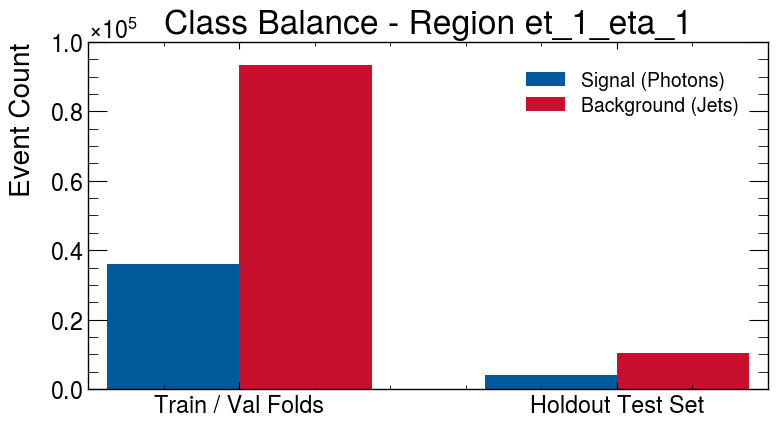

In [57]:
with open(CONFIG_PATH_1, "r") as f:
    config_dict_1 = yaml.safe_load(f)

if DATA_PATH.exists():
    config_dict_1["dataset"]["parameters"]["drive_path"] = str(DATA_PATH)

config_1 = NeuralRingerTrainerConfiguration.model_validate(config_dict_1)
trainer_1 = NeuralRingerTrainer(config_1)
full_dataset = trainer_1.full_dataset

# Locate dataset index matching TARGET_ET and TARGET_ETA
region_file_idx = None
for idx, path_str in enumerate(full_dataset.file_paths):
    iet, ieta = get_et_eta(path_str)
    if iet == TARGET_ET and ieta == TARGET_ETA:
        region_file_idx = idx
        break

if region_file_idx is None:
    raise FileNotFoundError(f"No dataset file matching et={TARGET_ET}, eta={TARGET_ETA} in {DATA_PATH}")

raw_features, raw_labels, region_file_path = full_dataset[region_file_idx]
print(f"Loaded dataset file: {region_file_path}")
print(f"Total events in region: {len(raw_labels):,}")

# Load test split indices from manifest
manifest = SplitManifest(str(MANIFEST_PATH))
if not manifest.exists():
    raise FileNotFoundError(f"Manifest not found at {MANIFEST_PATH}")

manifest.load()
test_indices, train_folds = manifest.get_region_splits(REGION_KEY)
test_indices = np.array(test_indices, dtype=int)

all_indices = np.arange(len(raw_labels))
train_val_mask = ~np.isin(all_indices, test_indices)
test_mask = np.isin(all_indices, test_indices)

test_features = raw_features[test_indices]
test_labels = raw_labels[test_indices]
train_val_labels = raw_labels[train_val_mask]

# Compute class counts
test_sig = int(np.sum(test_labels == 1))
test_bg = int(np.sum(test_labels == 0))
total_test = len(test_labels)

train_sig = int(np.sum(train_val_labels == 1))
train_bg = int(np.sum(train_val_labels == 0))
total_train = len(train_val_labels)

summary_df = pd.DataFrame([
    {
        "Partition": "Holdout Test Set",
        "Signal (Photons)": test_sig,
        "Background (Jets)": test_bg,
        "Total Events": total_test,
        "Signal Fraction": f"{test_sig / total_test:.2%}",
        "Background Fraction": f"{test_bg / total_test:.2%}",
    },
    {
        "Partition": "Train / Val Set",
        "Signal (Photons)": train_sig,
        "Background (Jets)": train_bg,
        "Total Events": total_train,
        "Signal Fraction": f"{train_sig / total_train:.2%}",
        "Background Fraction": f"{train_bg / total_train:.2%}",
    },
    {
        "Partition": "Full Region Data",
        "Signal (Photons)": test_sig + train_sig,
        "Background (Jets)": test_bg + train_bg,
        "Total Events": total_test + total_train,
        "Signal Fraction": f"{(test_sig + train_sig) / (total_test + total_train):.2%}",
        "Background Fraction": f"{(test_bg + train_bg) / (total_test + total_train):.2%}",
    }
])

display(summary_df)

# Plot class breakdown bar chart
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(2)
width = 0.35
ax.bar(x - width/2, [train_sig, test_sig], width, label="Signal (Photons)", color="#005A9C")
ax.bar(x + width/2, [train_bg, test_bg], width, label="Background (Jets)", color="#C8102E")
ax.set_xticks(x)
ax.set_xticklabels(["Train / Val Folds", "Holdout Test Set"])
ax.set_ylabel("Event Count")
ax.set_title(f"Class Balance - Region {REGION_KEY}")
ax.legend()
plt.tight_layout()
plt.show()


### 2. Feature Extraction & Distributions by Class Label
Defines the feature extractor (supporting raw columns and calculated variables like $E_{\text{ratio}} = (E_{\text{max1}} - E_{\text{max2}}) / (E_{\text{max1}} + E_{\text{max2}})$) and plots signal vs background histograms:



In [ ]:
def extract_feature_values(
    features: np.ndarray,
    names: np.ndarray,
    feat_name: str,
) -> np.ndarray:
    """Extracts raw feature column or calculates derived physics variables like Eratio.

    Args:
        features: Event feature matrix of shape (N, D).
        names: Column feature names array of shape (D,).
        feat_name: Target variable name.

    Returns:
        1D numpy array of values.
    """
    name_to_idx = {name: i for i, name in enumerate(names)}

    if feat_name.lower() in ["eratio", "eration", "l2_eratio"]:
        if "trig_L2_calo_emaxs1" in name_to_idx and "trig_L2_calo_e2tsts1" in name_to_idx:
            emaxs1 = features[:, name_to_idx["trig_L2_calo_emaxs1"]]
            e2tsts1 = features[:, name_to_idx["trig_L2_calo_e2tsts1"]]
            denom = emaxs1 + e2tsts1
            safe_denom = np.where(denom != 0.0, denom, 1.0)
            return np.where(denom != 0.0, (emaxs1 - e2tsts1) / safe_denom, 0.0)
        raise KeyError("Cannot compute Eratio: 'trig_L2_calo_emaxs1' and 'trig_L2_calo_e2tsts1' not found.")

    if feat_name in name_to_idx:
        return features[:, name_to_idx[feat_name]]

    raise KeyError(f"Feature '{feat_name}' not found in dataset columns.")

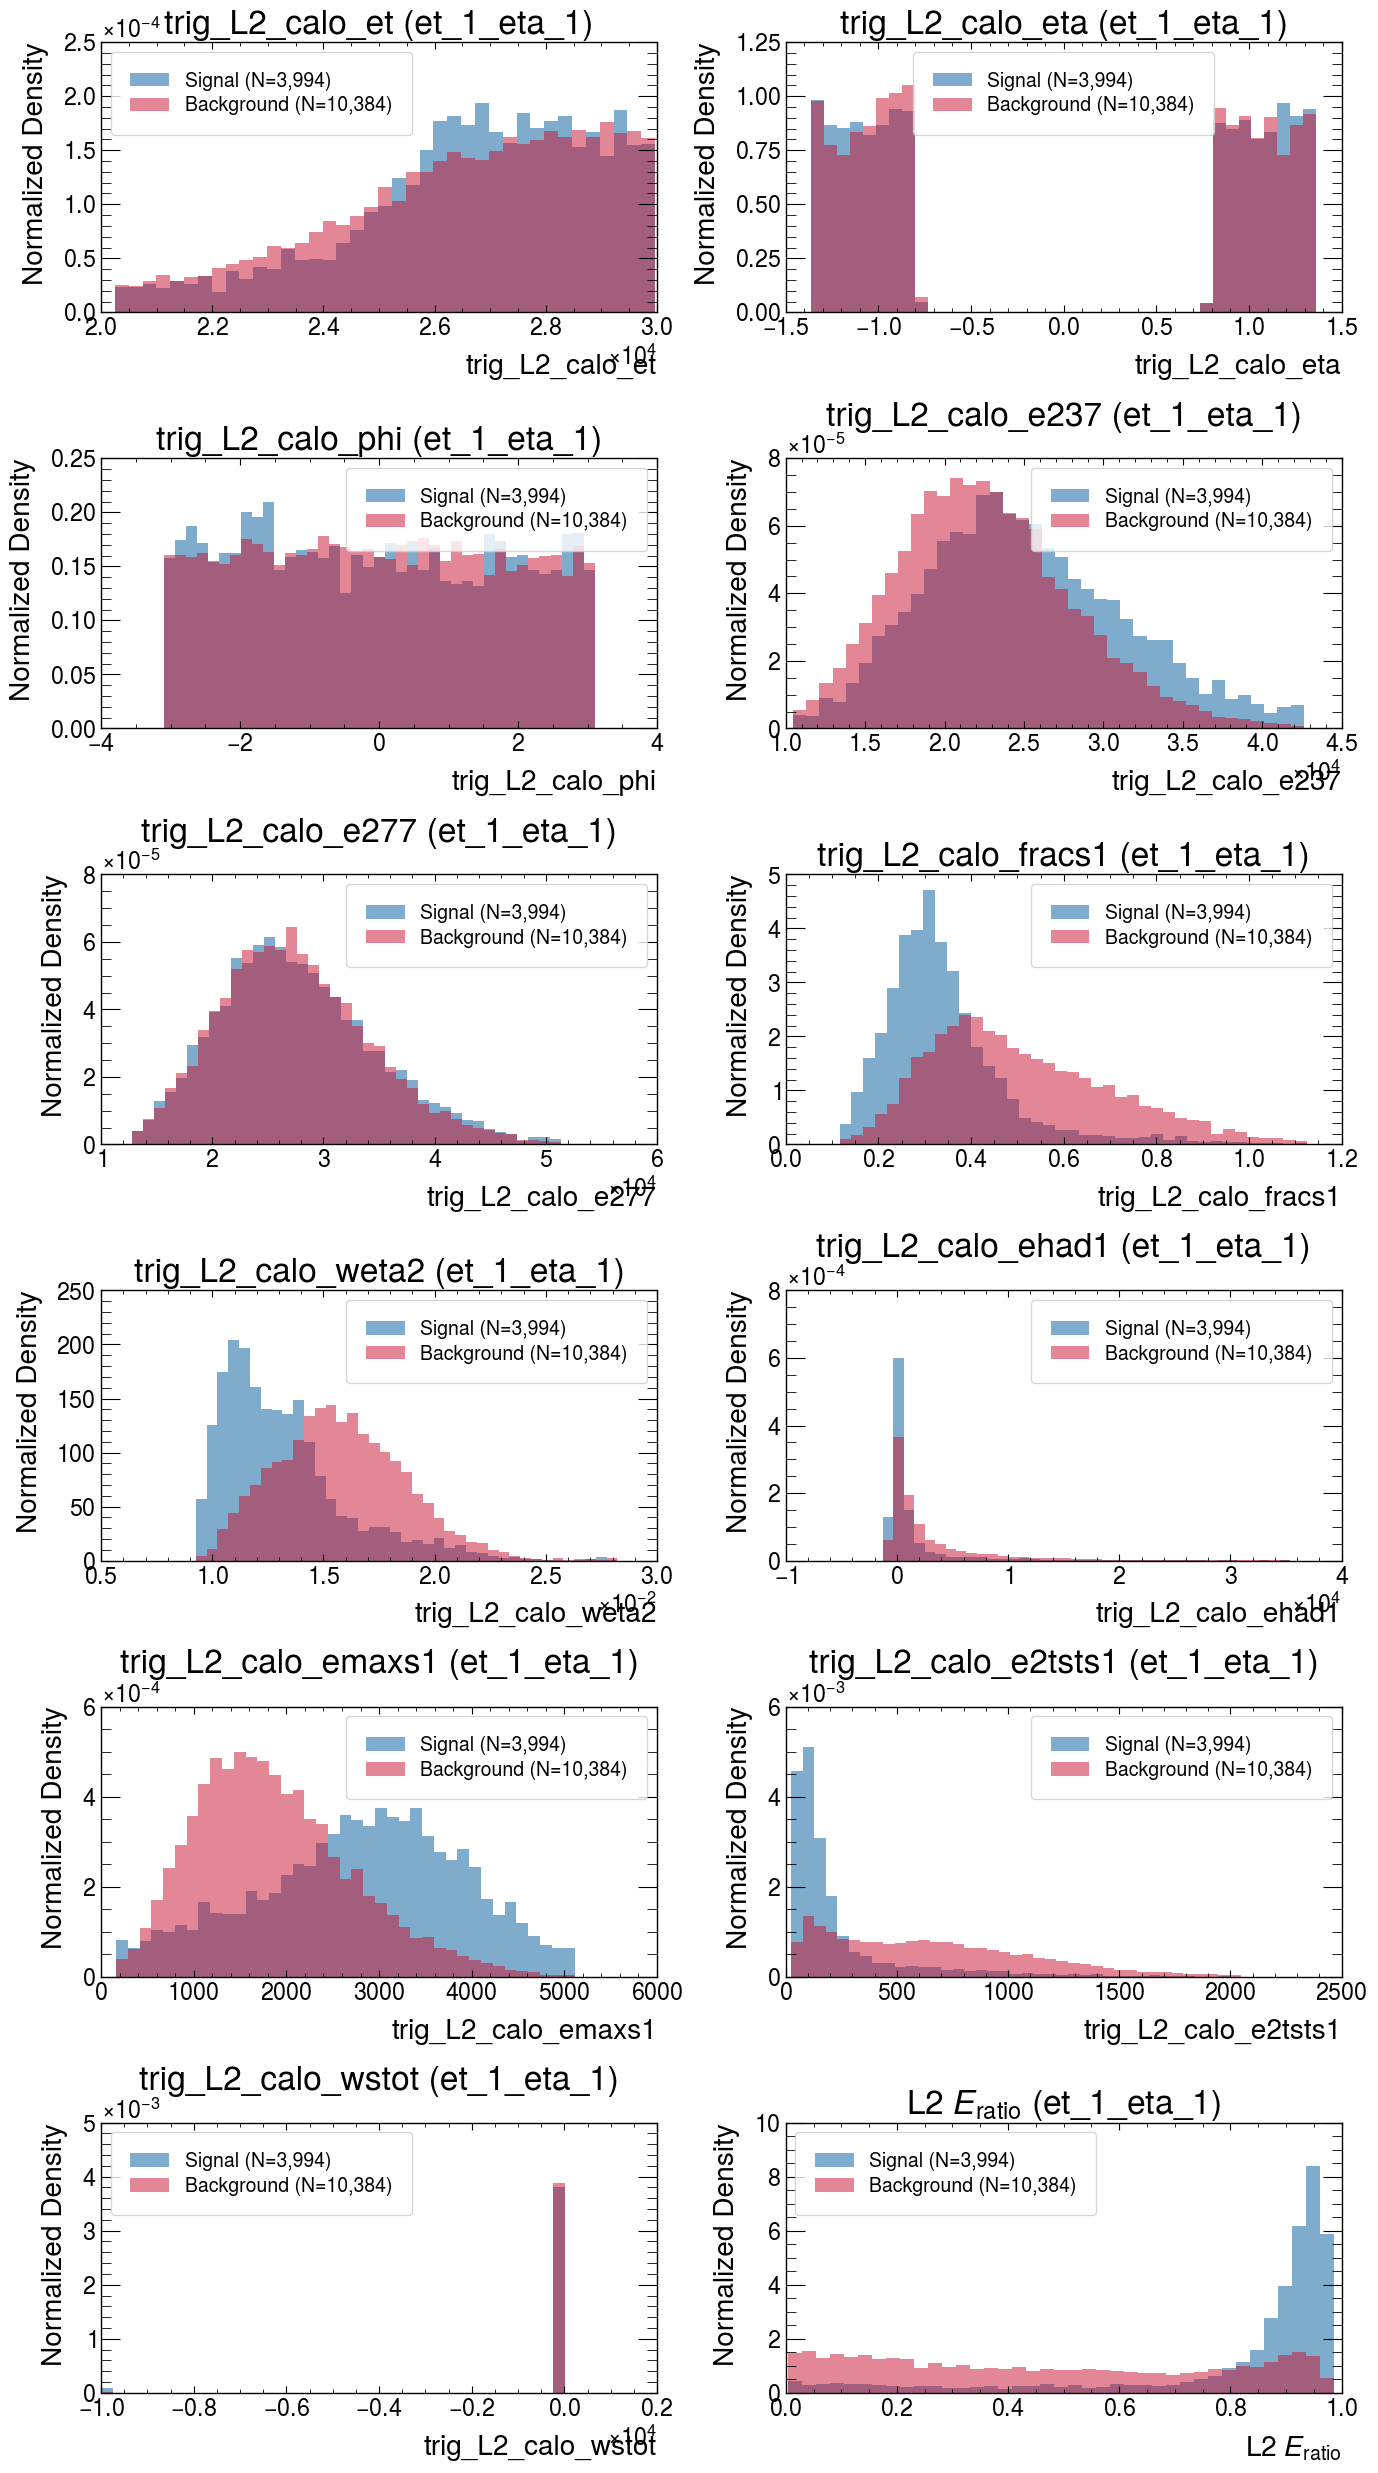

In [59]:
feature_names = full_dataset.feature_names

# Validate configured features
valid_features_to_plot = []
for f in FEATURES_TO_PLOT:
    try:
        _ = extract_feature_values(test_features[:5], feature_names, f)
        valid_features_to_plot.append(f)
    except KeyError as e:
        print(f"Skipping {f}: {e}")

n_features = len(valid_features_to_plot)
cols = 2
rows = (n_features + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(14, 4.2 * rows))
axes = np.array(axes).reshape(-1)

for idx, feat_name in enumerate(valid_features_to_plot):
    ax = axes[idx]
    values = extract_feature_values(test_features, feature_names, feat_name)

    val_sig = values[test_labels == 1]
    val_bg = values[test_labels == 0]

    val_sig = val_sig[np.isfinite(val_sig)]
    val_bg = val_bg[np.isfinite(val_bg)]

    all_vals = np.concatenate([val_sig, val_bg])
    low, high = np.percentile(all_vals, 0.5), np.percentile(all_vals, 99.5)
    bins = np.linspace(low, high, 40)

    ax.hist(val_sig, bins=bins, density=True, alpha=0.5, color="#005A9C", label=f"Signal (N={len(val_sig):,})")
    ax.hist(val_bg, bins=bins, density=True, alpha=0.5, color="#C8102E", label=f"Background (N={len(val_bg):,})")

    display_title = r"L2 $E_{\text{ratio}}$" if feat_name.lower() in ["eratio", "eration"] else feat_name
    ax.set_title(f"{display_title} ({REGION_KEY})")
    ax.set_xlabel(display_title)
    ax.set_ylabel("Normalized Density")
    ax.legend(frameon=True)

# Remove unused subplots if odd number
for j in range(idx + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


### 3. Model 1 Training Curves & Metric Evaluation
Scans fold files using [`ResultAggregator`](file:///home/pmourafr/egamma_master/src/core/Validation/ResultAggregator.py), extracts best SP checkpoint, and generates metric plots:



In [61]:
metrics_out_dir = OUTPUT_DIR / "Metrics_Model1"
metrics_out_dir.mkdir(parents=True, exist_ok=True)

aggregator_1 = ResultAggregator(RESULTS_PATH_1)
if not aggregator_1.has_region(TARGET_ET, TARGET_ETA):
    raise RuntimeError(f"No result records found in {RESULTS_PATH_1} for iet{TARGET_ET}.ieta{TARGET_ETA}")

best_model_1, best_rep_1, mean_sp_1, std_sp_1 = aggregator_1.get_best_model_for_region(TARGET_ET, TARGET_ETA)
print(f"Model 1 Best SP for {REGION_KEY}: {best_model_1['best_sp_value']:.4f} (Region Mean: {mean_sp_1:.4f} ± {std_sp_1:.4f})")
print(f"Best Fold: {best_model_1.get('fold')}, Best Init: {best_rep_1}")

# Generate training curves via PlotManager
plot_manager = PlotManager()
grouped_results_1 = aggregator_1.group_and_concat()
region_group_key = f"iet{TARGET_ET}.ieta{TARGET_ETA}"
df_region_1 = grouped_results_1.get(region_group_key)

if df_region_1 is not None and not df_region_1.empty:
    plot_manager.run_metrics_for_region(df_region_1, str(metrics_out_dir), TARGET_ET, TARGET_ETA)
    print(f"Generated metric figures saved under: {metrics_out_dir}")


Model 1 Best SP for et_1_eta_1: 0.8483 (Region Mean: 0.8445 ± 0.0035)
Best Fold: 6, Best Init: 1
Generated metric figures saved under: /eos/home-i04/p/pmourafr/egamma_master/Plots/SingleRegionValidation/Metrics_Model1


### 4. Model 1 Efficiency Validation & Operational Response Curves
Evaluates the best checkpoint weights on the holdout test set using [`HoldoutEvaluator`](file:///home/pmourafr/egamma_master/src/core/Validation/HoldoutEvaluator.py) and [`EfficiencyPlotter`](file:///home/pmourafr/egamma_master/src/core/Validation/EfficiencyPlotter.py):



In [65]:
validation_out_dir = OUTPUT_DIR / "Validation_Model1"
validation_out_dir.mkdir(parents=True, exist_ok=True)

model_1 = trainer_1.factory.create_model()
model_1.load_state_dict(best_model_1["best_weights"])
model_1.to(trainer_1.device)
model_1.eval()

evaluator = HoldoutEvaluator(default_target_pd=TARGET_PD)

ring_column_indices = full_dataset.ring_column_indices
if ring_column_indices is None:
    ring_column_indices = full_dataset.indexes

eval_result_1 = evaluator.evaluate(
    model=model_1,
    data=raw_features,
    target=raw_labels,
    test_indices=test_indices,
    ring_column_indices=ring_column_indices,
    device=trainer_1.device,
    target_pd=TARGET_PD,
)

print(f"Validation Holdout Performance for Model 1 ({REGION_KEY}):")
print(f"  Target Detection Efficiency (PD):   {eval_result_1.pd:.4f} ({eval_result_1.pd:.2%})")
print(f"  Calibrated Operating Cut (Th):       {eval_result_1.threshold:.4f}")
print(f"  False Alarm Rate (PF):               {eval_result_1.pf:.4f} ({eval_result_1.pf:.2%})")
print(f"  SP Index at Target Cut:              {eval_result_1.sp:.4f}")
print(f"  Area Under ROC Curve (AUC):          {eval_result_1.auc:.4f}")

# Render efficiency curves
eta_idx = int(np.where(feature_names == "trig_L2_calo_eta")[0][0])
et_idx = int(np.where(feature_names == "trig_L2_calo_et")[0][0])
eff_plotter = EfficiencyPlotter(et_idx, eta_idx)

eff_plotter.plot_regional_efficiency(
    result=eval_result_1,
    iet=TARGET_ET,
    ieta=TARGET_ETA,
    plot_dir=validation_out_dir,
    config_name=config_1.config_name,
)
print(f"Efficiency validation plots saved to: {validation_out_dir}")


Validation Holdout Performance for Model 1 (et_1_eta_1):
  Target Detection Efficiency (PD):   0.9424 (94.24%)
  Calibrated Operating Cut (Th):       0.0514
  False Alarm Rate (PF):               0.4578 (45.78%)
  SP Index at Target Cut:              0.7284
  Area Under ROC Curve (AUC):          0.9029
Efficiency validation plots saved to: /eos/home-i04/p/pmourafr/egamma_master/Plots/SingleRegionValidation/Validation_Model1


#### Model 1 Operating Points & Efficiency Table with Uncertainties
Consolidates operational metrics (Detection Efficiency, False Alarm, Background Rejection, Accuracy, and SP index) with binomial and error-propagated uncertainties for both default (0.5) and calibrated ($Th_{\text{target}}$) threshold cuts:


In [ ]:
m_def = StrategyMetrics.from_predictions(eval_result_1.predictions_default_threshold, eval_result_1.holdout_labels)
m_cal = StrategyMetrics.from_predictions(eval_result_1.predictions_calibrated_cut, eval_result_1.holdout_labels)

efficiency_table = pd.DataFrame([
    {
        "Operating Point": "Default Threshold (0.5000)",
        "Decision Threshold": "0.5000",
        "PD (Signal Eff)": f"{m_def.pd:.2%} ± {m_def.pd_uncertainty:.2%}",
        "PF (Fake Rate)": f"{m_def.pf:.2%} ± {m_def.pf_uncertainty:.2%}",
        "Background Rejection": f"{m_def.bg_eff:.2%} ± {m_def.bg_eff_uncertainty:.2%}",
        "Accuracy (Eff)": f"{m_def.eff:.2%} ± {m_def.eff_uncertainty:.2%}",
        "SP Index": f"{m_def.sp:.4f} ± {m_def.sp_uncertainty:.4f}",
        "TP": f"{m_def.tp:,}",
        "FP": f"{m_def.fp:,}",
        "TN": f"{m_def.tn:,}",
        "FN": f"{m_def.fn:,}",
    },
    {
        "Operating Point": f"Calibrated Cut (Target PD: {TARGET_PD*100:.2f}%)",
        "Decision Threshold": f"{eval_result_1.threshold:.4f}",
        "PD (Signal Eff)": f"{m_cal.pd:.2%} ± {m_cal.pd_uncertainty:.2%}",
        "PF (Fake Rate)": f"{m_cal.pf:.2%} ± {m_cal.pf_uncertainty:.2%}",
        "Background Rejection": f"{m_cal.bg_eff:.2%} ± {m_cal.bg_eff_uncertainty:.2%}",
        "Accuracy (Eff)": f"{m_cal.eff:.2%} ± {m_cal.eff_uncertainty:.2%}",
        "SP Index": f"{m_cal.sp:.4f} ± {m_cal.sp_uncertainty:.4f}",
        "TP": f"{m_cal.tp:,}",
        "FP": f"{m_cal.fp:,}",
        "TN": f"{m_cal.tn:,}",
        "FN": f"{m_cal.fn:,}",
    },
])
display(efficiency_table)


### 5. Quadrant Analysis: Model 1 vs Athena Trigger Linear Cuts
Compares predictions against the cut-based baseline using [`QuadrantAnalyzer`](file:///home/pmourafr/egamma_master/src/core/Validation/QuadrantAnalyzer.py) in `model_vs_cut` mode:



In [66]:
quadrant_cut_dir = OUTPUT_DIR / "Quadrant_Model_vs_Cut"
quadrant_cut_dir.mkdir(parents=True, exist_ok=True)

quadrant_cut_analyzer = QuadrantAnalyzer(
    config_path1=str(CONFIG_PATH_1),
    data_path1=str(RESULTS_PATH_1),
    manifest_path=str(MANIFEST_PATH),
    threshold_mode=THRESHOLD_MODE,
    efficiencies_csv=str(EFFICIENCIES_CSV) if EFFICIENCIES_CSV else None,
    default_target_pd=TARGET_PD,
    mode="model_vs_cut",
    working_point=WORKING_POINT,
    target_et=TARGET_ET,
    target_eta=TARGET_ETA,
)

cut_results = quadrant_cut_analyzer.run()
if not cut_results:
    raise RuntimeError(f"No quadrant results generated for {REGION_KEY}")

cut_res = cut_results[0]
s1 = cut_res.metrics_strategy1
s2 = cut_res.metrics_strategy2
qm = cut_res.overall_metrics

comparison_table = pd.DataFrame([
    {
        "Strategy": cut_res.strategy1_name,
        "PD (Signal Eff)": f"{s1.pd:.2%} ± {s1.pd_uncertainty:.2%}",
        "PF (Fake Rate)": f"{s1.pf:.2%} ± {s1.pf_uncertainty:.2%}",
        "SP Index": f"{s1.sp:.4f} ± {s1.sp_uncertainty:.4f}",
        "Accuracy": f"{s1.eff:.2%} ± {s1.eff_uncertainty:.2%}",
    },
    {
        "Strategy": cut_res.strategy2_name,
        "PD (Signal Eff)": f"{s2.pd:.2%} ± {s2.pd_uncertainty:.2%}",
        "PF (Fake Rate)": f"{s2.pf:.2%} ± {s2.pf_uncertainty:.2%}",
        "SP Index": f"{s2.sp:.4f} ± {s2.sp_uncertainty:.4f}",
        "Accuracy": f"{s2.eff:.2%} ± {s2.eff_uncertainty:.2%}",
    }
])
display(comparison_table)

quadrant_counts = pd.DataFrame({
    "Quadrant": [
        "Both Correct",
        f"Only {cut_res.strategy1_name} Correct",
        f"Only {cut_res.strategy2_name} Correct",
        "Both Wrong"
    ],
    "Event Count": [qm.both_correct, qm.model1_only_correct, qm.model2_only_correct, qm.both_wrong],
    "Ratio": [f"{qm.both_correct_ratio:.2%}", f"{qm.model1_only_correct_ratio:.2%}", f"{qm.model2_only_correct_ratio:.2%}", f"{qm.both_wrong_ratio:.2%}"]
})
print(f"McNemar p-value: {qm.mcnemar_p_value:.3e}")
display(quadrant_counts)

# Render standard quadrant figures
quadrant_plotter = QuadrantPlotter()
saved_cut_plots = quadrant_plotter.plot([cut_res], quadrant_cut_dir, file_format=PLOT_FORMAT)
print(f"Generated {sum(len(p) for p in saved_cut_plots.values())} quadrant plots under: {quadrant_cut_dir}")


,Strategy,PD (Signal Eff),PF (Fake Rate),SP Index,Accuracy
0,ModelV6_HighBatch_newExtraction_20_regions_100...,94.24%,45.78%,0.7284,65.34%
1,Athena Cut (Loose),77.77%,41.50%,0.6779,63.85%


McNemar p-value: 4.435e-03


,Quadrant,Event Count,Ratio
0,Both Correct,6512,45.29%
1,Only ModelV6_HighBatch_newExtraction_20_region...,2882,20.04%
2,Only Athena Cut (Loose) Correct,2669,18.56%
3,Both Wrong,2315,16.10%


Generated 13 quadrant plots under: /eos/home-i04/p/pmourafr/egamma_master/Plots/SingleRegionValidation/Quadrant_Model_vs_Cut


### 6. Signal & Background Feature Distributions by Model
Compares true class distributions against event selections for all models found across all mapped features:
- **Plot 1 (Signal Events)**: True Signal events shown with black dots (without error bars); ML model selections shown with full (filled) symbols with Poisson error bars; Athena Linear Cut selections shown with open (not full) symbols with Poisson error bars.
- **Plot 2 (Background Events)**: True Background events shown with black dots (without error bars); ML model selections shown with full (filled) symbols with Poisson error bars; Athena Linear Cut selections shown with open (not full) symbols with Poisson error bars.



In [67]:
def compute_ks_test_with_uncertainty(
    sample_ref: np.ndarray,
    sample_eval: np.ndarray,
    n_bootstraps: int = 100,
    random_seed: int = 42,
) -> tuple[float, float, float]:
    """Computes two-sample Kolmogorov-Smirnov statistic D, bootstrap uncertainty, and p-value.

    Args:
        sample_ref: Reference distribution sample.
        sample_eval: Evaluated model-selected sample.
        n_bootstraps: Number of bootstrap iterations for uncertainty estimation.
        random_seed: Random seed for reproducibility.

    Returns:
        Tuple of (ks_statistic, ks_uncertainty, p_value).
    """
    sample_ref = sample_ref[np.isfinite(sample_ref)]
    sample_eval = sample_eval[np.isfinite(sample_eval)]
    if len(sample_ref) == 0 or len(sample_eval) == 0:
        return 0.0, 0.0, 1.0

    ks_res = stats.ks_2samp(sample_ref, sample_eval)
    d_stat = float(ks_res.statistic)
    p_val = float(ks_res.pvalue)

    rng = np.random.default_rng(random_seed)
    n_ref = len(sample_ref)
    n_eval = len(sample_eval)
    d_boot = np.empty(n_bootstraps, dtype=float)
    for b in range(n_bootstraps):
        b_ref = rng.choice(sample_ref, size=n_ref, replace=True)
        b_eval = rng.choice(sample_eval, size=n_eval, replace=True)
        d_boot[b] = stats.ks_2samp(b_ref, b_eval).statistic
    d_unc = float(np.std(d_boot, ddof=1))
    return d_stat, d_unc, p_val


models_to_plot = [
    {
        "name": cut_res.strategy1_name,
        "preds": cut_res.preds_strategy1,
        "is_ml": True,
        "color": "#005A9C",
        "marker": "s",
    },
    {
        "name": cut_res.strategy2_name,
        "preds": cut_res.preds_strategy2,
        "is_ml": False,
        "color": "#E65100",
        "marker": "o",
    },
]

In [68]:
if ENABLE_MODEL2_COMPARISON and RESULTS_PATH_2.exists() and False:
    try:
        aggregator_2 = ResultAggregator(RESULTS_PATH_2)
        if aggregator_2.has_region(TARGET_ET, TARGET_ETA):
            best_model_2, _, _, _ = aggregator_2.get_best_model_for_region(TARGET_ET, TARGET_ETA)
            with open(CONFIG_PATH_2, "r") as f2:
                config_dict_2 = yaml.safe_load(f2)
            if DATA_PATH.exists():
                config_dict_2["dataset"]["parameters"]["drive_path"] = str(DATA_PATH)
            config_2 = NeuralRingerTrainerConfiguration.model_validate(config_dict_2)
            trainer_2 = NeuralRingerTrainer(config_2)
            model_2 = trainer_2.factory.create_model()
            model_2.load_state_dict(best_model_2["best_weights"])
            model_2.to(trainer_1.device)
            ring_indices_2 = trainer_2.full_dataset.ring_column_indices or trainer_2.full_dataset.indexes
            eval_res_2 = evaluator.evaluate(
                model=model_2,
                data=raw_features,
                target=raw_labels,
                test_indices=test_indices,
                ring_column_indices=ring_indices_2,
                device=trainer_1.device,
                target_pd=TARGET_PD,
            )
            models_to_plot.append({
                "name": f"Model 2 ({config_2.model.object_name})",
                "preds": eval_res_2.predictions_calibrated_cut,
                "is_ml": True,
                "color": "#2E7D32",
                "marker": "^",
            })
    except Exception as e:
        print(f"Note: Model 2 predictions not added: {e}")

### # FIGURE 1: SIGNAL DISTRIBUTIONS (True Signal = Black Dots, Models = With Error Bars)

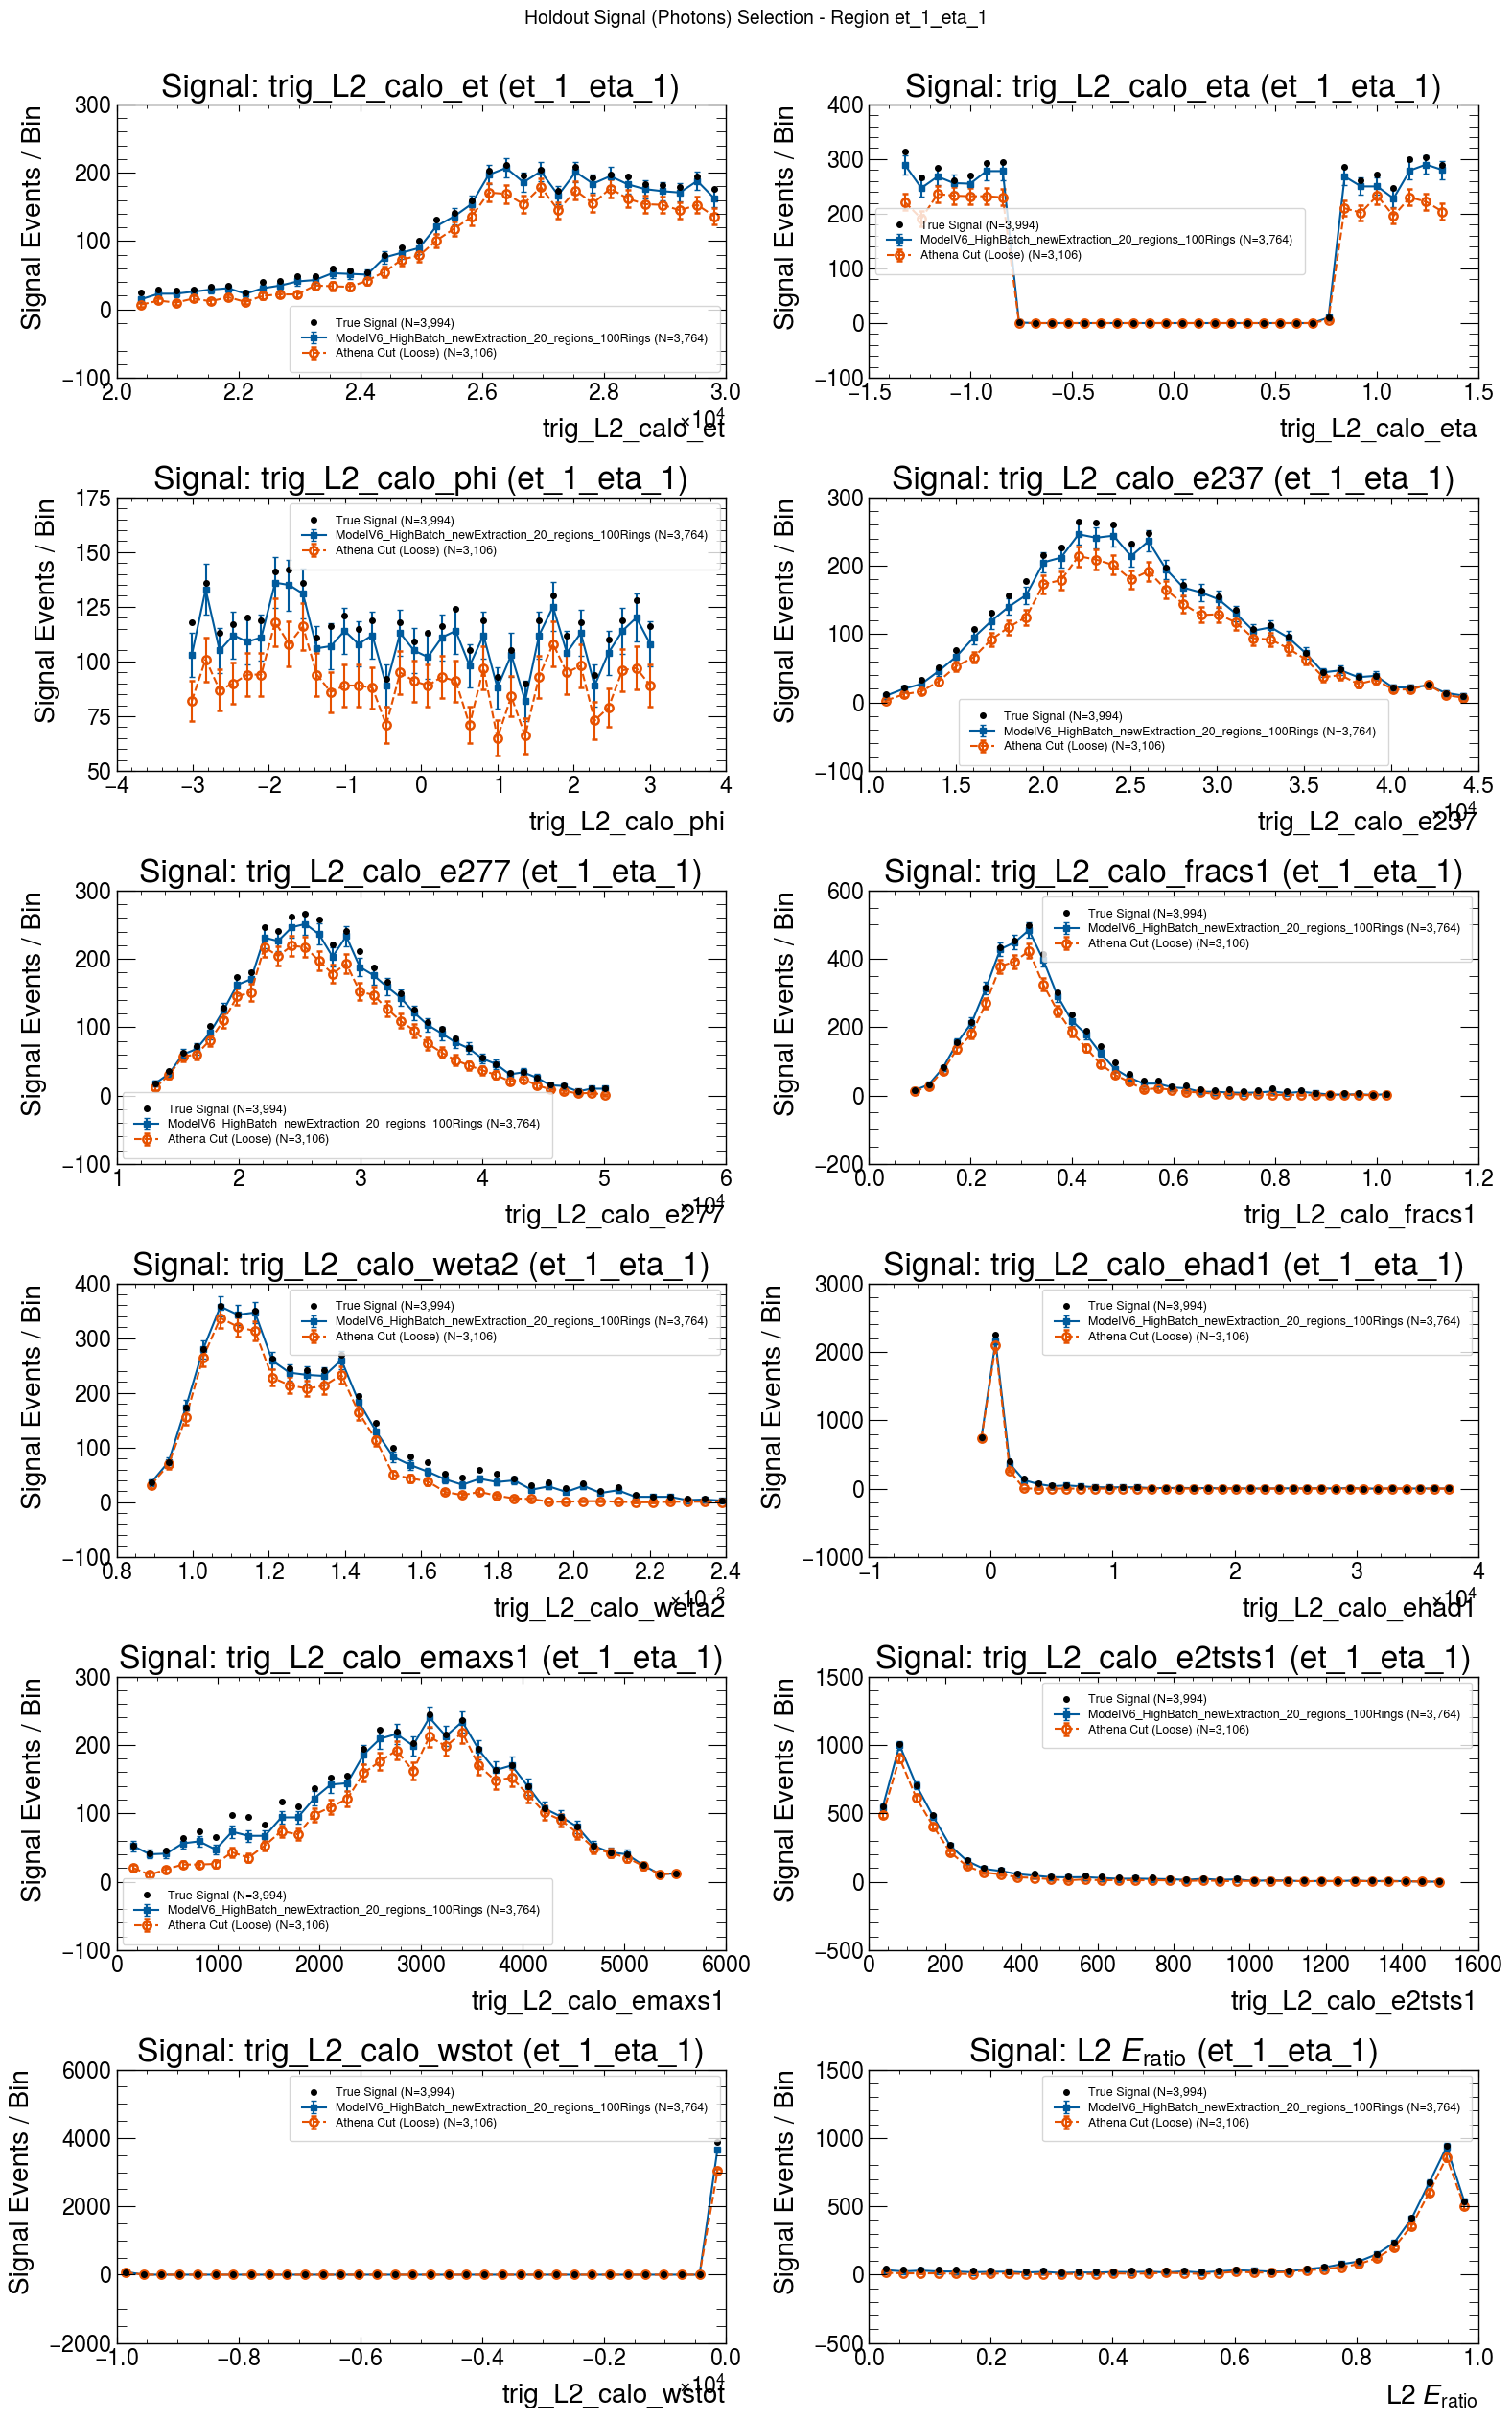

In [ ]:
n_features = len(valid_features_to_plot)
cols = 2
rows = (n_features + cols - 1) // cols

fig_sig, axes_sig = plt.subplots(rows, cols, figsize=(16, 4.2 * rows))
axes_sig = np.array(axes_sig).reshape(-1)

sig_ks_records = []

for idx, feat_name in enumerate(valid_features_to_plot):
    ax = axes_sig[idx]
    values = extract_feature_values(test_features, feature_names, feat_name)
    val_true_sig = values[test_labels == 1]
    val_true_sig = val_true_sig[np.isfinite(val_true_sig)]

    low = np.percentile(val_true_sig, 0.5)
    high = np.percentile(val_true_sig, 99.5)
    bins = np.linspace(low, high, 35)
    bin_centers = 0.5 * (bins[:-1] + bins[1:])

    # 1. True Signal: Ground truth points without error bars
    counts_true_sig, _ = np.histogram(val_true_sig, bins=bins)
    ax.plot(
        bin_centers, counts_true_sig,
        "o", color="black", markersize=4, zorder=5,
        label=f"True Signal (N={len(val_true_sig):,})"
    )

    # 2. Model Selections: Signal events accepted by each model with Poisson error bars
    for m in models_to_plot:
        val_m_sig = values[(test_labels == 1) & (m["preds"] == 1)]
        val_m_sig = val_m_sig[np.isfinite(val_m_sig)]
        counts_m_sig, _ = np.histogram(val_m_sig, bins=bins)
        err_m_sig = np.sqrt(counts_m_sig)

        d_stat, d_unc, p_val = compute_ks_test_with_uncertainty(val_true_sig, val_m_sig)
        sig_ks_records.append({
            "Feature": feat_name,
            "Strategy": m["name"],
            "True Count": len(val_true_sig),
            "Selected Count": len(val_m_sig),
            "KS Distance (D)": f"{d_stat:.4f} ± {d_unc:.4f}",
            "p-value": f"{p_val:.3e}",
            "Distribution Equality": "Consistent (p >= 0.05)" if p_val >= 0.05 else "Distinct (p < 0.05)",
        })

        label_text = f"{m['name']} (N={len(val_m_sig):,}, KS={d_stat:.3f}±{d_unc:.3f})"
        if m["is_ml"]:
            # Full (filled) symbols with error bars for ML models
            ax.errorbar(
                bin_centers, counts_m_sig, yerr=err_m_sig,
                fmt=m["marker"], color=m["color"],
                markerfacecolor=m["color"], markeredgecolor=m["color"],
                linestyle="-", linewidth=1.5, markersize=5, capsize=2,
                label=label_text
            )
        else:
            # Not full (open/unfilled) symbols with error bars for Linear Cut
            ax.errorbar(
                bin_centers, counts_m_sig, yerr=err_m_sig,
                fmt=m["marker"], color=m["color"],
                markerfacecolor="none", markeredgecolor=m["color"], markeredgewidth=1.8,
                linestyle="--", linewidth=1.5, markersize=6, capsize=2,
                label=label_text
            )

    display_title = r"L2 $E_{\text{ratio}}$" if feat_name.lower() in ["eratio", "eration"] else feat_name
    ax.set_title(f"Signal: {display_title} ({REGION_KEY})")
    ax.set_xlabel(display_title)
    ax.set_ylabel("Signal Events / Bin")
    ax.legend(frameon=True, fontsize=9)

for j in range(idx + 1, len(axes_sig)):
    fig_sig.delaxes(axes_sig[j])

fig_sig.suptitle(f"Holdout Signal (Photons) Selection - Region {REGION_KEY}", fontsize=14, y=1.002)
plt.tight_layout()
plt.show()

sig_ks_df = pd.DataFrame(sig_ks_records)
print(f"Kolmogorov-Smirnov Test Comparison: Signal Selections vs True Signal ({REGION_KEY}):")
display(sig_ks_df)


### FIGURE 2: BACKGROUND DISTRIBUTIONS (True Bg = Black Dots, Models = With Error Bars)


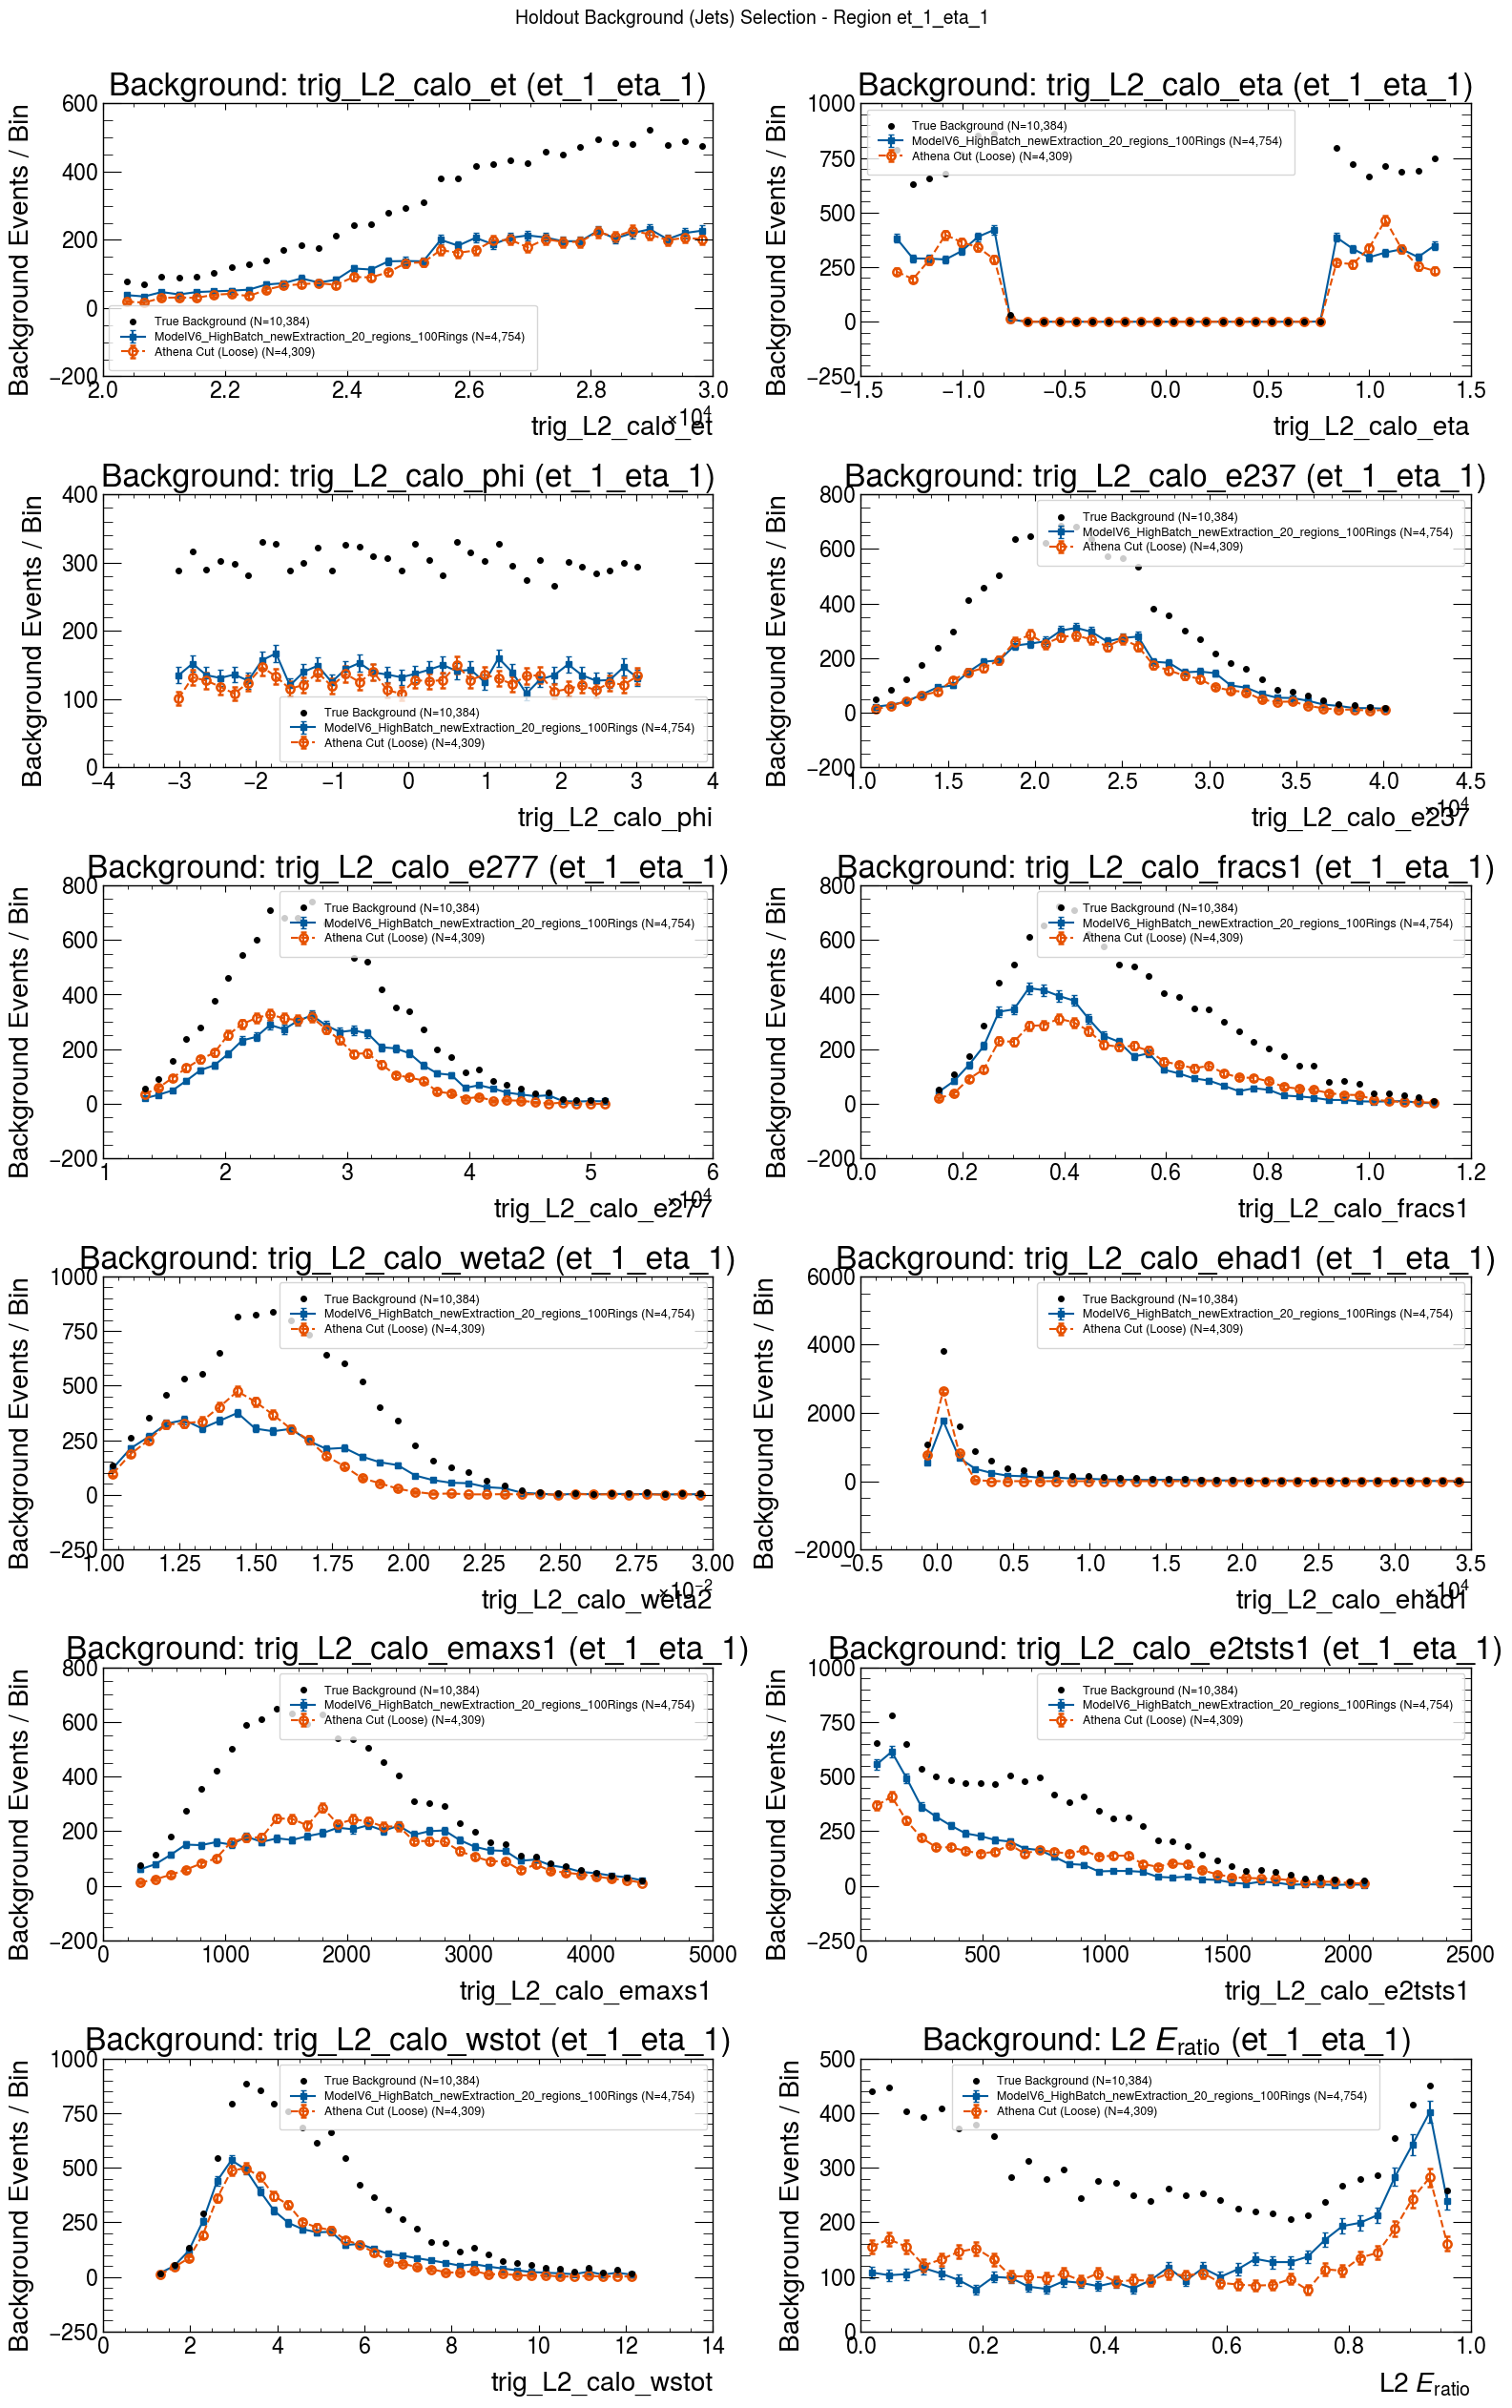

In [70]:
fig_bg, axes_bg = plt.subplots(rows, cols, figsize=(16, 4.2 * rows))
axes_bg = np.array(axes_bg).reshape(-1)

bg_ks_records = []

for idx, feat_name in enumerate(valid_features_to_plot):
    ax = axes_bg[idx]
    values = extract_feature_values(test_features, feature_names, feat_name)
    val_true_bg = values[test_labels == 0]
    val_true_bg = val_true_bg[np.isfinite(val_true_bg)]

    low = np.percentile(val_true_bg, 0.5)
    high = np.percentile(val_true_bg, 99.5)
    bins = np.linspace(low, high, 35)
    bin_centers = 0.5 * (bins[:-1] + bins[1:])

    # 1. True Background: Ground truth points without error bars
    counts_true_bg, _ = np.histogram(val_true_bg, bins=bins)
    ax.plot(
        bin_centers, counts_true_bg,
        "o", color="black", markersize=4, zorder=5,
        label=f"True Background (N={len(val_true_bg):,})"
    )

    # 2. Model Selections: Background events accepted by each model with Poisson error bars
    for m in models_to_plot:
        val_m_bg = values[(test_labels == 0) & (m["preds"] == 1)]
        val_m_bg = val_m_bg[np.isfinite(val_m_bg)]
        counts_m_bg, _ = np.histogram(val_m_bg, bins=bins)
        err_m_bg = np.sqrt(counts_m_bg)

        d_stat, d_unc, p_val = compute_ks_test_with_uncertainty(val_true_bg, val_m_bg)
        bg_ks_records.append({
            "Feature": feat_name,
            "Strategy": m["name"],
            "True Count": len(val_true_bg),
            "Selected Count": len(val_m_bg),
            "KS Distance (D)": f"{d_stat:.4f} ± {d_unc:.4f}",
            "p-value": f"{p_val:.3e}",
            "Distribution Equality": "Consistent (p >= 0.05)" if p_val >= 0.05 else "Distinct (p < 0.05)",
        })

        label_text = f"{m['name']} (N={len(val_m_bg):,}, KS={d_stat:.3f}±{d_unc:.3f})"
        if m["is_ml"]:
            # Full (filled) symbols with error bars for ML models
            ax.errorbar(
                bin_centers, counts_m_bg, yerr=err_m_bg,
                fmt=m["marker"], color=m["color"],
                markerfacecolor=m["color"], markeredgecolor=m["color"],
                linestyle="-", linewidth=1.5, markersize=5, capsize=2,
                label=label_text
            )
        else:
            # Not full (open/unfilled) symbols with error bars for Linear Cut
            ax.errorbar(
                bin_centers, counts_m_bg, yerr=err_m_bg,
                fmt=m["marker"], color=m["color"],
                markerfacecolor="none", markeredgecolor=m["color"], markeredgewidth=1.8,
                linestyle="--", linewidth=1.5, markersize=6, capsize=2,
                label=label_text
            )

    display_title = r"L2 $E_{\text{ratio}}$" if feat_name.lower() in ["eratio", "eration"] else feat_name
    ax.set_title(f"Background: {display_title} ({REGION_KEY})")
    ax.set_xlabel(display_title)
    ax.set_ylabel("Background Events / Bin")
    ax.legend(frameon=True, fontsize=9)

for j in range(idx + 1, len(axes_bg)):
    fig_bg.delaxes(axes_bg[j])

fig_bg.suptitle(f"Holdout Background (Jets) Selection - Region {REGION_KEY}", fontsize=14, y=1.002)
plt.tight_layout()
plt.show()

bg_ks_df = pd.DataFrame(bg_ks_records)
print(f"Kolmogorov-Smirnov Test Comparison: Background Selections vs True Background ({REGION_KEY}):")
display(bg_ks_df)


### 7. Comparative Quadrant Analysis: Model 1 vs Model 2
Loads a secondary model configuration and executes holdout quadrant benchmarking across both neural architectures:



In [72]:
quadrant_m2m_dir = OUTPUT_DIR / "Quadrant_Model_vs_Model"
quadrant_m2m_dir.mkdir(parents=True, exist_ok=True)

quadrant_m2m_analyzer = QuadrantAnalyzer(
    config_path1=str(CONFIG_PATH_1),
    data_path1=str(RESULTS_PATH_1),
    config_path2=str(CONFIG_PATH_2),
    data_path2=str(RESULTS_PATH_2),
    manifest_path=str(MANIFEST_PATH),
    threshold_mode=THRESHOLD_MODE,
    efficiencies_csv=str(EFFICIENCIES_CSV) if EFFICIENCIES_CSV else None,
    default_target_pd=TARGET_PD,
    mode="model_vs_model",
    target_et=TARGET_ET,
    target_eta=TARGET_ETA,
)

m2m_results = quadrant_m2m_analyzer.run()
if not m2m_results:
    print(f"No comparative results generated for Model 1 vs Model 2 in {REGION_KEY}")
else:
    m2m_res = m2m_results[0]
    s1 = m2m_res.metrics_strategy1
    s2 = m2m_res.metrics_strategy2
    qm = m2m_res.overall_metrics

    m2m_table = pd.DataFrame([
        {
            "Model": m2m_res.strategy1_name,
            "PD (Signal Eff)": f"{s1.pd:.2%} ± {s1.pd_uncertainty:.2%}",
            "PF (Fake Rate)": f"{s1.pf:.2%} ± {s1.pf_uncertainty:.2%}",
            "SP Index": f"{s1.sp:.4f} ± {s1.sp_uncertainty:.4f}",
            "Accuracy": f"{s1.eff:.2%} ± {s1.eff_uncertainty:.2%}",
        },
        {
            "Model": m2m_res.strategy2_name,
            "PD (Signal Eff)": f"{s2.pd:.2%} ± {s2.pd_uncertainty:.2%}",
            "PF (Fake Rate)": f"{s2.pf:.2%} ± {s2.pf_uncertainty:.2%}",
            "SP Index": f"{s2.sp:.4f} ± {s2.sp_uncertainty:.4f}",
            "Accuracy": f"{s2.eff:.2%} ± {s2.eff_uncertainty:.2%}",
        }
    ])
    display(m2m_table)

    m2m_quadrant_counts = pd.DataFrame({
        "Quadrant": [
            "Both Correct",
            f"Only {m2m_res.strategy1_name} Correct",
            f"Only {m2m_res.strategy2_name} Correct",
            "Both Wrong"
        ],
        "Event Count": [qm.both_correct, qm.model1_only_correct, qm.model2_only_correct, qm.both_wrong],
        "Ratio": [f"{qm.both_correct_ratio:.2%}", f"{qm.model1_only_correct_ratio:.2%}", f"{qm.model2_only_correct_ratio:.2%}", f"{qm.both_wrong_ratio:.2%}"]
    })
    print(f"McNemar p-value: {qm.mcnemar_p_value:.3e}")
    display(m2m_quadrant_counts)

    # Save plots
    saved_m2m_plots = quadrant_plotter.plot([m2m_res], quadrant_m2m_dir, file_format=PLOT_FORMAT)
    print(f"Generated {sum(len(p) for p in saved_m2m_plots.values())} plots under: {quadrant_m2m_dir}")


,Model,PD (Signal Eff),PF (Fake Rate),SP Index,Accuracy
0,ModelV6_HighBatch_newExtraction_20_regions_100...,94.24%,45.78%,0.7284,65.34%
1,ModelV6_HighBatch_newExtraction_20_regions_50R...,94.24%,44.71%,0.7346,66.11%


McNemar p-value: 2.887e-03


,Quadrant,Event Count,Ratio
0,Both Correct,8768,60.98%
1,Only ModelV6_HighBatch_newExtraction_20_region...,626,4.35%
2,Only ModelV6_HighBatch_newExtraction_20_region...,737,5.13%
3,Both Wrong,4247,29.54%


Generated 13 plots under: /eos/home-i04/p/pmourafr/egamma_master/Plots/SingleRegionValidation/Quadrant_Model_vs_Model
